# FMTS Workshop — paper tables and figures

A compact, reproducible notebook for the tables and figure reported in **From Temporal Foundation to World Models: Counterfactual Probing with Exact Ground Truth**.

All numerical results are read from `results/metrics/`. The notebook does not load foundation models or rerun experiments. Tables are exported as CSV files to `results/paper_artifacts/`; Figure 1 is exported to `results/figures/`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "results").exists() and (ROOT.parent / "results").exists():
    ROOT = ROOT.parent
METRICS = ROOT / "results" / "metrics"
TABLES = ROOT / "results" / "paper_artifacts"
FIGURES = ROOT / "results" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

pooled = pd.read_csv(METRICS / "summary_pooled.csv")
by_structure = pd.read_csv(METRICS / "summary_by_structure.csv")
per_episode = pd.read_csv(METRICS / "per_episode.csv", low_memory=False)
print(f"Loaded {len(per_episode):,} model-episode rows from {METRICS}")


Loaded 217,200 model-episode rows from results/metrics


In [ ]:
MODELS = ["chronos-2", "tabpfn-ts", "tirex-2", "moirai-1.1", "moirai-2.0", "timesfm-2.5"]
DISPLAY = {
    "chronos-2": "Chronos-2", "tabpfn-ts": "TabPFN-TS", "tirex-2": "TiRex-2",
    "moirai-1.1": "Moirai-1.1", "moirai-2.0": "Moirai-2.0", "timesfm-2.5": "TimesFM-2.5",
    "dotime-pfn": "DoT-PFN", "tabpfn-static-adjustment": "Static TabPFN",
}
INTERFACE = {"chronos-2":"P1", "tabpfn-ts":"P1", "tirex-2":"P1", "moirai-1.1":"P1", "moirai-2.0":"P1", "timesfm-2.5":"P1*"}
EM = "—"

pooled_nz = pd.read_csv(METRICS / "summary_pooled_nonzero.csv")

def row(model, regime, source=None):
    source = pooled if source is None else source
    x = source[(source.model == model) & (source.regime == regime)]
    return None if x.empty else x.iloc[0]

def ci(r, metric):
    if r is None or not np.isfinite(r.get(metric, np.nan)): return EM
    return f"{r[metric]:.3f} [{r[metric+'_lo']:.3f}, {r[metric+'_hi']:.3f}]"

def save(df, name):
    path = TABLES / f"{name}.csv"
    df.to_csv(path)
    print("Saved:", path)
    display(df)


## Table 1 — Identifiability results

Effect Delta RMSE is the primary correctness metric. Coverage is interpreted relative to 0.80.


In [3]:
rows=[]
for model in MODELS:
    r=row(model,"identifiability")
    rows.append({"Model":DISPLAY[model],"Interface":INTERFACE[model],"Usage Gap":ci(r,"usage_gap"),"Effect Delta RMSE ↓":ci(r,"effect_rmse"),"Dir. Acc. ↑":ci(r,"direction_accuracy"),"Cov. 80%":ci(r,"coverage_80")})
r=row("zero","identifiability")
rows.append({"Model":"Zero-effect anchors","Interface":EM,"Usage Gap":ci(r,"usage_gap"),"Effect Delta RMSE ↓":ci(r,"effect_rmse"),"Dir. Acc. ↑":EM,"Cov. 80%":EM})
table1=pd.DataFrame(rows).set_index("Model")
save(table1,"table1_identifiability")


Saved: results/paper_artifacts/table1_identifiability.csv


,Interface,Usage Gap,Effect Delta RMSE ↓,Dir. Acc. ↑,Cov. 80%
Model,,,,,
Chronos-2,P1,"0.124 [0.118, 0.129]","0.337 [0.321, 0.355]","0.807 [0.793, 0.821]","0.769 [0.761, 0.777]"
TabPFN-TS,P1,"0.121 [0.117, 0.125]","0.357 [0.333, 0.383]","0.848 [0.835, 0.860]","0.800 [0.792, 0.808]"
TiRex-2,P1,"0.115 [0.108, 0.121]","0.344 [0.326, 0.363]","0.746 [0.731, 0.761]","0.725 [0.716, 0.733]"
Moirai-1.1,P1,"0.031 [0.031, 0.032]","0.469 [0.440, 0.500]","0.504 [0.494, 0.514]","0.665 [0.656, 0.674]"
Moirai-2.0,P1,"0.006 [0.006, 0.006]","0.466 [0.437, 0.497]","0.491 [0.474, 0.508]","0.678 [0.669, 0.687]"
TimesFM-2.5,P1*,"0.328 [0.318, 0.339]","0.460 [0.427, 0.500]","0.862 [0.850, 0.874]","0.668 [0.659, 0.677]"
Zero-effect anchors,—,"0.000 [0.000, 0.000]","0.466 [0.437, 0.497]",—,—


In [ ]:
rows = []

for model in MODELS:
    r = row(model, "identifiability", source=pooled_nz)
    rows.append({
        "Model": DISPLAY[model],
        "Interface": INTERFACE[model],
        "Usage Gap": ci(r, "usage_gap"),
        "Effect Delta RMSE ↓": ci(r, "effect_rmse"),
        "Dir. Acc. ↑": ci(r, "direction_accuracy"),
        "Cov. 80%": ci(r, "coverage_80"),
    })

r = row("zero", "identifiability", source=pooled_nz)

rows.append({
    "Model": "Zero-effect anchors",
    "Interface": EM,
    "Usage Gap": ci(r, "usage_gap"),
    "Effect Delta RMSE ↓": ci(r, "effect_rmse"),
    "Dir. Acc. ↑": EM,
    "Cov. 80%": EM,
})

table1_nz = pd.DataFrame(rows).set_index("Model")
save(table1_nz, "table1_identifiability_nonzero")

print("E[|tau|] on nonzero-effect episodes:",
      round(r["true_effect_scale"], 3))

## Table 2 — Conditioning interfaces and protocol coverage


In [4]:
table2=pd.DataFrame([
["Chronos-2","P1","✓","✓","✓"],["TabPFN-TS","P1","✓","✓","✓"],["TiRex-2","P1","✓","✓","✓"],
["Moirai-1.1","P1","✓","✓",EM],["Moirai-2.0","P1","✓","✓",EM],["TimesFM-2.5","P1*","✓","✓",EM],
["Toto-1.0","P2","limited†","limited†",EM],["Chronos-Bolt","interface-limited",EM,EM,EM],
["TiRex-1","interface-limited",EM,EM,EM],["Sundial","interface-limited",EM,EM,EM],
["Static TabPFN","causal ref.","✓",EM,EM],["DoT-PFN","causal ref.","✓","✓","✓"]],
columns=["Model","Interface","Identifiability","Continuous in-window","Continuous post-window"]).set_index("Model")
save(table2,"table2_interfaces")


Saved: results/paper_artifacts/table2_interfaces.csv


,Interface,Identifiability,Continuous in-window,Continuous post-window
Model,,,,
Chronos-2,P1,✓,✓,✓
TabPFN-TS,P1,✓,✓,✓
TiRex-2,P1,✓,✓,✓
Moirai-1.1,P1,✓,✓,—
Moirai-2.0,P1,✓,✓,—
TimesFM-2.5,P1*,✓,✓,—
Toto-1.0,P2,limited†,limited†,—
Chronos-Bolt,interface-limited,—,—,—
TiRex-1,interface-limited,—,—,—


## Table 3 — Metric definitions


In [5]:
table3=pd.DataFrame([
["Usage Gap",r"mean(|tau_hat|)"],["Effect Delta RMSE ↓",r"sqrt(mean((tau_hat - tau)^2))"],
["Effect Delta MAE ↓",r"mean(|tau_hat - tau|)"],["Effect-direction accuracy ↑",r"mean(sign(tau_hat) = sign(tau)), |tau| >= 0.1"],
["Central-80% coverage",r"mean(q10 <= Y_do <= q90); target = 0.80"],["Approx. CRPS ↓",r"2 × mean pinball loss over q=0.1,...,0.9"],
["Effect Profile ↓",r"Effect Delta MAE within each offset bin"]], columns=["Metric","Definition"]).set_index("Metric")
save(table3,"table3_metrics")


Saved: results/paper_artifacts/table3_metrics.csv


,Definition
Metric,
Usage Gap,mean(|tau_hat|)
Effect Delta RMSE ↓,sqrt(mean((tau_hat - tau)^2))
Effect Delta MAE ↓,mean(|tau_hat - tau|)
Effect-direction accuracy ↑,"mean(sign(tau_hat) = sign(tau)), |tau| >= 0.1"
Central-80% coverage,mean(q10 <= Y_do <= q90); target = 0.80
Approx. CRPS ↓,"2 × mean pinball loss over q=0.1,...,0.9"
Effect Profile ↓,Effect Delta MAE within each offset bin


## Table 4 — Identifiability by causal structure


In [6]:
structures=[("bi_variate","Bivariate"),("mediator","Mediator"),("observed_confounder","Obs. conf."),("unobserved_confounder","Unobs. conf."),("back_door","Back-door"),("front_door","Front-door"),("instrumental_variable","IV"),("confounder_mediator","Conf. + med.")]
rows=[]
for model,label in [(m,DISPLAY[m]) for m in MODELS]+[("zero","TrajMean / AR(1) / Zero"),("tabpfn-static-adjustment","Static TabPFN"),("dotime-pfn","DoT-PFN")]:
    out={"Model":label}
    for structure,col in structures:
        r=by_structure[(by_structure.model==model)&(by_structure.regime=="identifiability")&(by_structure.structure==structure)]
        rr=None if r.empty else r.iloc[0]
        metric="reference_effect_rmse" if model in {"tabpfn-static-adjustment","dotime-pfn"} else "effect_rmse"
        out[col]=np.nan if rr is None else rr.get(metric,np.nan)
    rows.append(out)
table4=pd.DataFrame(rows).set_index("Model")
table4.to_csv(TABLES / "table4_effect_rmse_by_structure.csv")
display(table4.style.format("{:.3f}", na_rep=EM))


,Bivariate,Mediator,Obs. conf.,Unobs. conf.,Back-door,Front-door,IV,Conf. + med.
Model,,,,,,,,
Chronos-2,0.510,0.082,0.095,0.156,0.511,0.247,0.479,0.244
TabPFN-TS,0.518,0.116,0.088,0.117,0.582,0.219,0.520,0.247
TiRex-2,0.474,0.075,0.100,0.139,0.554,0.271,0.484,0.267
Moirai-1.1,0.715,0.044,0.060,0.040,0.771,0.250,0.707,0.286
Moirai-2.0,0.712,0.013,0.013,0.012,0.768,0.250,0.706,0.284
TimesFM-2.5,0.508,0.309,0.291,0.363,0.708,0.493,0.485,0.376
TrajMean / AR(1) / Zero,0.712,0.000,0.000,0.000,0.767,0.248,0.706,0.285
Static TabPFN,0.712,0.061,0.079,0.000,0.527,0.211,0.706,0.216
DoT-PFN,0.785,0.381,0.390,0.375,0.866,0.489,0.788,0.488


## Table 5 — Probabilistic calibration across regimes


In [7]:
regimes=[("identifiability","Identifiability"),("in_window","Continuous In-window"),("post_window","Continuous Post-window")]
cal_models=MODELS+["dotime-pfn"]
data=[]
for model in cal_models:
    values=[]
    for regime,_ in regimes:
        r=row(model,regime)
        values += [ci(r,"coverage_80"),ci(r,"crps_approx")]
    data.append(values)
cols=pd.MultiIndex.from_product([[x[1] for x in regimes],["80% Cov.","CRPS ↓"]])
table5=pd.DataFrame(data,index=[DISPLAY[m] for m in cal_models],columns=cols)
table5.index.name="Model"
save(table5,"table5_calibration")


Saved: results/paper_artifacts/table5_calibration.csv


Identifiability                        Continuous In-window  \
                         80% Cov.                CRPS ↓              80% Cov.   
Model                                                                           
Chronos-2    0.769 [0.761, 0.777]  0.266 [0.261, 0.271]  0.793 [0.778, 0.807]   
TabPFN-TS    0.800 [0.792, 0.808]  0.275 [0.269, 0.280]  0.677 [0.660, 0.694]   
TiRex-2      0.725 [0.716, 0.733]  0.267 [0.262, 0.272]  0.715 [0.699, 0.731]   
Moirai-1.1   0.665 [0.656, 0.674]  0.319 [0.312, 0.327]  0.717 [0.701, 0.732]   
Moirai-2.0   0.678 [0.669, 0.687]  0.312 [0.304, 0.319]  0.673 [0.656, 0.690]   
TimesFM-2.5  0.668 [0.659, 0.677]  0.314 [0.307, 0.321]  0.593 [0.576, 0.611]   
DoT-PFN      0.787 [0.779, 0.794]  0.334 [0.327, 0.342]  0.797 [0.783, 0.812]   

                                  Continuous Post-window                        
                           CRPS ↓               80% Cov.                CRPS ↓  
Model                                                                           
Chronos-2    0.578 [0.541, 0.626]   0.838 [0.825, 0.852]  0.645 [0.547, 0.794]  
TabPFN-TS    0.827 [0.723, 0.979]   0.860 [0.847, 0.872]  0.641 [0.548, 0.770]  
TiRex-2      0.669 [0.614, 0.749]   0.809 [0.795, 0.823]  0.643 [0.555, 0.772]  
Moirai-1.1   0.663 [0.617, 0.715]                      —                     —  
Moirai-2.0   0.639 [0.601, 0.683]                      —                     —  
TimesFM-2.5  0.896 [0.812, 1.006]                      —                     —  
DoT-PFN      0.718 [0.652, 0.803]   0.871 [0.859, 0.883]  0.665 [0.563, 0.809]

## Effect-profile helpers

For stochastic models, absolute errors are computed per seed and then averaged. Confidence intervals use 10,000 episode bootstrap resamples with seed 42, matching the paper.


In [8]:
IN_EDGES=[0,10,20,30,40,50,60]
IN_LABELS=["0–9","10–19","20–29","30–39","40–49","50–59"]
POST_EDGES=[0,10,20,30,40,50,60,70,80,np.inf]
POST_LABELS=["0–9","10–19","20–29","30–39","40–49","50–59","60–69","70–79","80+"]

def bootstrap_mean(x,n_boot=10_000,seed=42,block=500):
    x=np.asarray(x,float); x=x[np.isfinite(x)]; rng=np.random.default_rng(seed); reps=[]
    for start in range(0,n_boot,block):
        size=min(block,n_boot-start); idx=rng.integers(0,len(x),size=(size,len(x)))
        reps.append(x[idx].mean(axis=1))
    lo,hi=np.percentile(np.concatenate(reps),[2.5,97.5])
    return x.mean(),lo,hi,len(x)

def profile_data(regime,model,nonzero=False):
    edges,labels=(IN_EDGES,IN_LABELS) if regime=="in_window" else (POST_EDGES,POST_LABELS)
    d=per_episode[(per_episode.regime==regime)&(per_episode.model==model)].copy()
    d["offset"]=d.query_offset_from_start if regime=="in_window" else d.query_step-d.intervention_end
    d["bin"]=pd.cut(d.offset,edges,labels=labels,right=False)
    d["error"]=(d.implied_effect_metric-d.true_effect).abs()
    if nonzero: d=d[d.true_effect!=0]
    # Mean over inference seeds for each benchmark episode.
    e=d.groupby(["episode","bin"],observed=True).error.mean().reset_index()
    return {label:bootstrap_mean(e.loc[e.bin==label,"error"]) for label in labels}

def truth_profile(regime,nonzero=False):
    edges,labels=(IN_EDGES,IN_LABELS) if regime=="in_window" else (POST_EDGES,POST_LABELS)
    d=per_episode[per_episode.regime==regime].drop_duplicates("episode").copy()
    d["offset"]=d.query_offset_from_start if regime=="in_window" else d.query_step-d.intervention_end
    d["bin"]=pd.cut(d.offset,edges,labels=labels,right=False)
    if nonzero: d=d[d.true_effect!=0]
    return {label:bootstrap_mean(d.loc[d.bin==label,"true_effect"].abs()) for label in labels}

def profile_table(regime,models,nonzero=False,with_ci=False):
    labels=IN_LABELS if regime=="in_window" else POST_LABELS
    rows=[]
    for model,label in models:
        vals=profile_data(regime,model,nonzero)
        rows.append([label]+[(f"{vals[b][0]:.3f} [{vals[b][1]:.3f}, {vals[b][2]:.3f}]" if with_ci else vals[b][0]) for b in labels])
    anchor=truth_profile(regime,nonzero)
    return pd.DataFrame(rows,columns=["Model"]+labels).set_index("Model"),anchor


## Table 6 — Continuous in-window Effect Profile


In [9]:
table6,anchor_in=profile_table("in_window",[(m,DISPLAY[m]) for m in MODELS],with_ci=True)
table6.loc["Zero-effect anchor"]=[f"{anchor_in[b][0]:.3f}" for b in IN_LABELS]
table6.loc["n episodes"]=[anchor_in[b][3] for b in IN_LABELS]
save(table6,"table6_in_window_effect_profile")


Saved: results/paper_artifacts/table6_in_window_effect_profile.csv


,0–9,10–19,20–29,30–39,40–49,50–59
Model,,,,,,
Chronos-2,"0.381 [0.341, 0.422]","0.526 [0.465, 0.590]","0.618 [0.510, 0.763]","0.547 [0.453, 0.653]","0.610 [0.495, 0.737]","0.461 [0.333, 0.611]"
TabPFN-TS,"0.720 [0.552, 0.973]","0.733 [0.638, 0.834]","0.986 [0.698, 1.440]","0.757 [0.589, 0.946]","0.679 [0.544, 0.825]","0.605 [0.436, 0.789]"
TiRex-2,"0.449 [0.393, 0.509]","0.648 [0.570, 0.733]","0.685 [0.561, 0.837]","0.558 [0.465, 0.664]","0.620 [0.497, 0.761]","0.478 [0.338, 0.632]"
Moirai-1.1,"0.385 [0.335, 0.437]","0.543 [0.466, 0.628]","0.627 [0.456, 0.906]","0.471 [0.381, 0.576]","0.512 [0.400, 0.635]","0.379 [0.262, 0.513]"
Moirai-2.0,"0.360 [0.310, 0.412]","0.526 [0.448, 0.612]","0.613 [0.429, 0.919]","0.468 [0.383, 0.562]","0.504 [0.392, 0.630]","0.400 [0.281, 0.534]"
TimesFM-2.5,"0.755 [0.631, 0.911]","0.884 [0.771, 1.006]","1.050 [0.792, 1.426]","0.819 [0.670, 0.985]","0.804 [0.656, 0.966]","0.710 [0.499, 0.943]"
Zero-effect anchor,0.356,0.516,0.594,0.441,0.467,0.366
n episodes,797,749,690,436,257,71


## Table 7 — Aggregate Continuous results


In [10]:
rows=[]
for model,label in [(m,DISPLAY[m]) for m in MODELS]+[("zero","Zero-effect anchor")]:
    out={"Model":label}
    for regime,prefix in [("in_window","In-window"),("post_window","Post-window")]:
        r=row(model,regime)
        out[(prefix,"Usage Gap")]=np.nan if r is None else r.usage_gap
        out[(prefix,"Effect Delta RMSE ↓")]=np.nan if r is None else r.effect_rmse
        out[(prefix,"Effect Delta MAE ↓")]=np.nan if r is None else r.effect_mae
    rows.append(out)
table7=pd.DataFrame(rows).set_index("Model")
table7.columns=pd.MultiIndex.from_tuples(table7.columns)
table7.to_csv(TABLES/"table7_aggregate_continuous.csv")
display(table7.style.format("{:.3f}",na_rep=EM))


## Table 8 — Post-intervention Effect Profile


In [11]:
post_models=[("chronos-2","Chronos-2"),("tirex-2","TiRex-2"),("tabpfn-ts","TabPFN-TS / anchor")]
table8,anchor_post=profile_table("post_window",post_models)
table8.loc["n episodes"]=[anchor_post[b][3] for b in POST_LABELS]
nonzero_truth=truth_profile("post_window",True)
table8.loc["n nonzero effect"]=[nonzero_truth[b][3] for b in POST_LABELS]
table8.to_csv(TABLES/"table8_post_window_effect_profile.csv")
display(table8.style.format("{:.3f}",na_rep=EM))


,0–9,10–19,20–29,30–39,40–49,50–59,60–69,70–79,80+
Model,,,,,,,,,
Chronos-2,0.487,0.250,0.324,0.357,0.150,0.076,0.197,0.081,0.189
TiRex-2,0.471,0.287,0.283,0.412,0.618,0.115,0.552,0.129,0.193
TabPFN-TS / anchor,0.293,0.114,0.297,0.259,0.071,0.006,0.149,0.015,0.054
n episodes,688.000,575.000,463.000,387.000,286.000,225.000,145.000,114.000,117.000
n nonzero effect,457.000,308.000,164.000,127.000,87.000,44.000,30.000,15.000,21.000


## Table 9 — Persistence-only diagnostic


In [12]:
table9,_=profile_table("post_window",post_models,nonzero=True)
table9.to_csv(TABLES/"table9_persistence_only.csv")
display(table9.style.format("{:.3f}",na_rep=EM))


,0–9,10–19,20–29,30–39,40–49,50–59,60–69,70–79,80+
Model,,,,,,,,,
Chronos-2,0.614,0.346,0.704,0.892,0.318,0.097,0.716,0.122,0.842
TiRex-2,0.622,0.412,0.537,1.004,1.759,0.158,2.212,0.203,0.694
TabPFN-TS / anchor,0.441,0.213,0.838,0.788,0.234,0.032,0.721,0.116,0.303


## Figure 1 — Effect Delta MAE by offset


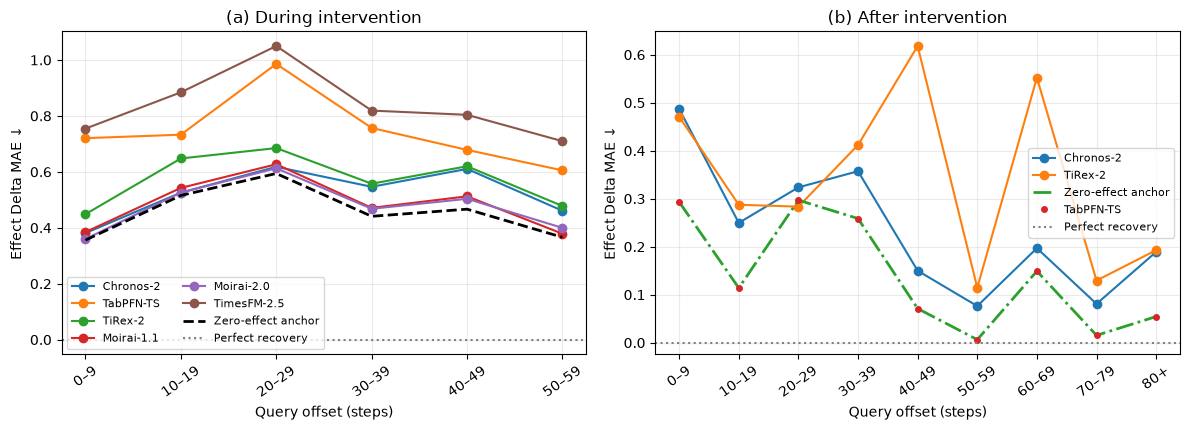

In [13]:
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
colors=plt.cm.tab10.colors
# During intervention
for j,model in enumerate(MODELS):
    vals=profile_data("in_window",model)
    axes[0].plot(IN_LABELS,[vals[b][0] for b in IN_LABELS],marker="o",label=DISPLAY[model],color=colors[j])
axes[0].plot(IN_LABELS,[anchor_in[b][0] for b in IN_LABELS],color="black",ls="--",lw=2,label="Zero-effect anchor")
axes[0].axhline(0,color="gray",ls=":",label="Perfect recovery")
axes[0].set_title("(a) During intervention")
# After intervention
for j,model in enumerate(["chronos-2","tirex-2"]):
    vals=profile_data("post_window",model)
    axes[1].plot(POST_LABELS,[vals[b][0] for b in POST_LABELS],marker="o",label=DISPLAY[model],color=colors[j])
axes[1].plot(POST_LABELS,[anchor_post[b][0] for b in POST_LABELS],color="tab:green",ls="-.",lw=2,label="Zero-effect anchor")
tabpfn_post=profile_data("post_window","tabpfn-ts")
axes[1].plot(POST_LABELS,[tabpfn_post[b][0] for b in POST_LABELS],color="tab:red",marker="o",ls="none",ms=4,label="TabPFN-TS")
axes[1].axhline(0,color="gray",ls=":",label="Perfect recovery")
axes[1].set_title("(b) After intervention")
for ax in axes:
    ax.set_xlabel("Query offset (steps)"); ax.set_ylabel("Effect Delta MAE ↓"); ax.grid(alpha=.25); ax.tick_params(axis='x',rotation=35)
axes[0].legend(fontsize=8,ncol=2); axes[1].legend(fontsize=8)
fig.tight_layout()
for ext in ("pdf","png"):
    fig.savefig(FIGURES/f"figure1_effect_delta_mae.{ext}",dpi=300,bbox_inches="tight")
plt.show()


## Table 10 — Software versions and release chronology


In [14]:
table10=pd.DataFrame([
["Chronos-2","chronos-forecasting 2.3.1","Oct. 20, 2025","ruled out"],
["TabPFN-TS","tabpfn-time-series 1.2.0","May 12, 2026","ruled out"],
["TimesFM-2.5","timesfm 2.0.2","Sep. 15, 2025","ruled out"],
["Toto-1.0","toto-ts 0.2.0","May 21, 2025","ruled out"],
["Moirai-1.1","uni2ts 2.0.0","Jun. 14, 2024","ruled out"],
["Moirai-2.0","uni2ts 2.0.0","Aug. 6, 2025","ruled out"],
["TiRex-2","tirex-2 0.2.1","Jul. 1, 2026","postdates archive; not disclosed as training source"],
["Static TabPFN","tabpfn 8.3.0","May 12, 2026","ruled out"],
["DoT-PFN","public interventional checkpoint","Jun. 25, 2026","trained on interventional data by design"]],
columns=["Model","Software","Public release","Exact-suite exposure"]).set_index("Model")
save(table10,"table10_software_versions")


Saved: results/paper_artifacts/table10_software_versions.csv


,Software,Public release,Exact-suite exposure
Model,,,
Chronos-2,chronos-forecasting 2.3.1,"Oct. 20, 2025",ruled out
TabPFN-TS,tabpfn-time-series 1.2.0,"May 12, 2026",ruled out
TimesFM-2.5,timesfm 2.0.2,"Sep. 15, 2025",ruled out
Toto-1.0,toto-ts 0.2.0,"May 21, 2025",ruled out
Moirai-1.1,uni2ts 2.0.0,"Jun. 14, 2024",ruled out
Moirai-2.0,uni2ts 2.0.0,"Aug. 6, 2025",ruled out
TiRex-2,tirex-2 0.2.1,"Jul. 1, 2026",postdates archive; not disclosed as training s...
Static TabPFN,tabpfn 8.3.0,"May 12, 2026",ruled out
DoT-PFN,public interventional checkpoint,"Jun. 25, 2026",trained on interventional data by design


## Audit note: PDF versus frozen artifacts

The notebook recomputes values from the frozen metric files. Two small differences from the current PDF are intentionally visible:

- Table 8 reports 163 nonzero effects for post-window offset 20–29, while the frozen episode data contain 164. Consequently, three Table 9 entries differ slightly (e.g. Chronos-2 is 0.704 from data versus 0.708 in the PDF).
- Several Table 6 bootstrap limits differ in the third decimal place, although all point estimates match. The PDF appears to have used a different bootstrap draw sequence or implementation for this table.

These should be reconciled before the camera-ready version.


## Reproduction checks

These assertions connect the generated artifacts to representative values printed in the PDF. They fail loudly if the underlying aggregate files change.


In [15]:
assert round(row("chronos-2","identifiability").effect_rmse,3)==0.337
assert round(row("timesfm-2.5","identifiability").usage_gap,3)==0.328
assert round(row("chronos-2","in_window").effect_rmse,3)==1.210
assert round(row("chronos-2","post_window").effect_rmse,3)==2.044
assert round(profile_data("in_window","chronos-2")["0–9"][0],3)==0.381
assert round(profile_data("post_window","tirex-2")["40–49"][0],3)==0.618
print("All representative paper-value checks passed.")


All representative paper-value checks passed.
